In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import os

os.environ.setdefault("KMP_DUPLICATE_LIB_OK", "TRUE")

import pathlib
import sys

import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import numpy as np
import torch
from matplotlib.lines import Line2D

ROOT = pathlib.Path().resolve().parent
sys.path.insert(0, str(ROOT / "src"))

import const
import domain
import json_util
import pde_residual
import pinn_training
import piston_flow
import plot_util

plot_util.apply_plot_style()

RESULT = ROOT / "result" / "pinn_piston_flow"
FIGURE = RESULT / "figure"
FIGURE.mkdir(parents=True, exist_ok=True)

RESUME_TRAINING = "auto"

FIELDS = ("u", "G")
KNOWN = {"nu": const.PISTON_NU}
DOMAIN = domain.BoxDomain([0.0, 0.0], [1.0, const.PISTON_T_MAX], power=[1.0, const.PISTON_T_POWER])
SEEDS = tuple(range(const.N_REPEATS))
DELTA = const.PISTON_DELTA
_x, _w = np.polynomial.legendre.leggauss(const.PISTON_QUAD_N)
QUAD_R, QUAD_W = 0.5 * (_x + 1.0), 0.5 * _w

PINN = {"hidden": const.EXPLORE_HIDDEN,
        "loss_balance": {"method": "grad_norm", "every": const.GRAD_NORM_EVERY, "alpha": const.GRAD_NORM_ALPHA},
        "log_input": {"axis": 1, "eps": const.LOG_T_EPS, "keep_linear": True}}

U_C = float(piston_flow.plug_scale(DELTA))


def wall(x, y):
    return torch.stack([(1.0 - x[:, 0]) * y[:, 0], y[:, 1]], dim=1)


def axis(F, X):
    return [pde_residual.grad(F(X)["u"], X)[:, 0]]


def initial(F, X):
    return [F(X)["u"] - U_C * torch.tanh((1.0 - X[:, 0]) / DELTA)]


def flow_rate(F, X):
    r = torch.as_tensor(QUAD_R, dtype=X.dtype, device=X.device)
    w = torch.as_tensor(QUAD_W, dtype=X.dtype, device=X.device)
    u = F(torch.stack([r.repeat(X.shape[0]), X[:, 1].repeat_interleave(r.numel())], dim=1))["u"]
    return [(w * 2.0 * r * u.reshape(X.shape[0], -1)).sum(dim=1) - 1.0]


BOUNDARY = [{"name": "axis", "axis": 0, "side": "lo", "residual": axis},
            {"name": "initial", "axis": 1, "side": "lo", "residual": initial},
            {"name": "flow_rate", "axis": 0, "side": "lo", "residual": flow_rate}]

U_C_CHANNEL = float(piston_flow.channel_plug_scale(DELTA))


def initial_channel(F, X):
    return [F(X)["u"] - U_C_CHANNEL * torch.tanh((1.0 - X[:, 0]) / DELTA)]


def flow_rate_channel(F, X):
    y = torch.as_tensor(QUAD_R, dtype=X.dtype, device=X.device)
    w = torch.as_tensor(QUAD_W, dtype=X.dtype, device=X.device)
    u = F(torch.stack([y.repeat(X.shape[0]), X[:, 1].repeat_interleave(y.numel())], dim=1))["u"]
    return [(w * u.reshape(X.shape[0], -1)).sum(dim=1) - 1.0]


BOUNDARY_CHANNEL = [{"name": "centerline", "axis": 0, "side": "lo", "residual": axis},
                    {"name": "initial", "axis": 1, "side": "lo", "residual": initial_channel},
                    {"name": "flow_rate", "axis": 0, "side": "lo", "residual": flow_rate_channel}]

ALPHA, COEF = piston_flow.project(lambda r: piston_flow.smooth_plug(r, DELTA), const.PISTON_N_PROJ)
LAMBDA_CH, COEF_CH = piston_flow.channel_project(lambda y: piston_flow.channel_smooth_plug(y, DELTA),
                                                 const.PISTON_N_PROJ)
R_EVAL = np.linspace(0.0, 1.0, const.PISTON_EVAL_R_N)
T_EVAL = np.linspace(0.0, const.PISTON_T_MAX, const.PISTON_EVAL_T_N)
T_LOG = np.concatenate([[0.0], np.geomspace(1e-4, const.PISTON_T_MAX, const.PISTON_EVAL_T_LOG)])
T_SNAP = np.asarray(const.PISTON_SNAP_T)


def reference(velocity, pressure_gradient, *coef):
    return {"u_snap": velocity(R_EVAL[:, None], T_SNAP[None], *coef),
            "G": pressure_gradient(T_EVAL, *coef),
            "G_log": pressure_gradient(T_LOG, *coef)}


PROBLEMS = {"pipe": {"pde": [pde_residual.pipe_startup], "boundary": BOUNDARY, "coord": "r", "G_steady": 8.0,
                     "ref": reference(piston_flow.expansion_velocity, piston_flow.expansion_pressure_gradient,
                                      ALPHA, COEF)},
            "channel": {"pde": [pde_residual.channel_startup], "boundary": BOUNDARY_CHANNEL, "coord": "y",
                        "G_steady": 3.0,
                        "ref": reference(piston_flow.channel_expansion_velocity,
                                         piston_flow.channel_expansion_pressure_gradient, LAMBDA_CH, COEF_CH)}}


def predict_fields(trainer):
    def u_on(r, t):
        X = np.column_stack([m.ravel() for m in np.meshgrid(r, t, indexing="ij")])
        return trainer.evaluate(X)["u"].reshape(r.size, t.size)

    G_on = lambda t: trainer.evaluate(np.column_stack([np.zeros_like(t), t]))["G"]
    return {"u": u_on(R_EVAL, T_EVAL), "u_log": u_on(R_EVAL, T_LOG), "u_snap": u_on(R_EVAL, T_SNAP),
            "G": G_on(T_EVAL), "G_log": G_on(T_LOG)}


def run_path(case, seed):
    return RESULT / case / f"seed_{seed}.json"


def load_runs(case):
    return [json_util.load_json(run_path(case, s)) for s in SEEDS]


def train_run(case, seed, force):
    ckpt = run_path(case, seed).with_suffix(".pt")
    ckpt.parent.mkdir(parents=True, exist_ok=True)
    if force:
        ckpt.unlink(missing_ok=True)
    P = PROBLEMS[case]
    trainer = pinn_training.PINNTraining(num_node=const.PISTON_NUM_NODE, fields=FIELDS, pde=P["pde"], known=KNOWN,
                                         domain=DOMAIN, boundary=P["boundary"], transform=wall,
                                         seed=seed, checkpoint_path=ckpt,
                                         resume=False if force else RESUME_TRAINING, **PINN)
    res = trainer.train()
    rec = {"case": case, "seed": seed, "pred": predict_fields(trainer),
           "history": res["history"], "best": res["best"], "loss": res["loss"], "terms": res["terms"],
           "weights": res["weights"], "wall_seconds": res["wall_seconds"], "config": res["config"]}
    json_util.save_json(run_path(case, seed), rec)
    print(f"{case} seed {seed}: wall={rec['wall_seconds'] / 60:.1f} min", flush=True)


def train(case, run=False, force=False):
    for seed in SEEDS:
        if run or force or not run_path(case, seed).exists():
            train_run(case, seed, force)


TERM_COLORS = {"momentum_x": "tab:green", "axis": "tab:purple", "centerline": "tab:purple", "initial": "tab:red",
               "flow_rate": "tab:brown"}


def term_names(run):
    return [*run["config"]["terms"]["pde"], *run["config"]["terms"]["bc"]]


def plot_loss(case):
    runs = load_runs(case)
    fig, axes = plt.subplots(2, len(runs), figsize=(6 * len(runs), 10), sharex=True, sharey="row")
    for j, r in enumerate(runs):
        h = r["history"]
        ax = axes[0, j]
        pinn_training.PINNTraining.plot_loss(h, ax=ax, best_epoch=pinn_training.PINNTraining.best_axis(r["best"]))
        for k in term_names(r):
            ax.semilogy(h["epoch"], h[f"train_term_{k}"], color=TERM_COLORS.get(k), lw=1, label=f"train {k}")
            axes[1, j].semilogy(h["epoch"], h[f"weight_{k}"], color=TERM_COLORS.get(k), label=k)
        ax.set_ylabel("loss (total weighted)")
        ax.set_title(f"seed {r['seed']}")
        axes[1, j].set_xlabel("epoch")
        axes[1, j].set_ylabel("loss weight")
        axes[1, j].yaxis.set_major_locator(mticker.LogLocator(subs=(1.0, 2.0, 5.0)))
        axes[1, j].yaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f"{v:g}"))
        axes[1, j].yaxis.set_minor_formatter(mticker.NullFormatter())
    axes[0, 0].legend(fontsize=10)
    axes[1, 0].legend(fontsize=10)
    fig.suptitle(f"{case}: loss history")
    fig.tight_layout()
    fig.savefig(FIGURE / f"{case}_loss.png")
    plt.show()
    for r in runs:
        h, b = r["history"], r["best"]
        i = max(n for n, (e, ph) in enumerate(zip(h["epoch"], h["phase"])) if e == b["epoch"] and ph == b["phase"])
        print(f"seed {r['seed']} best epoch {b['epoch']}, validation terms: "
              + "  ".join(f"{k}={h[f'val_term_{k}'][i]:.2e}" for k in term_names(r))
              + "   weights: " + "  ".join(f"{k}={v:.3g}" for k, v in r["weights"].items()))


def plot_performance(case):
    runs = load_runs(case)
    P = PROBLEMS[case]
    ref, pred = P["ref"], np.asarray(runs[0]["pred"]["u_snap"])
    fig, axes = plt.subplots(1, 2, figsize=(12, 5))
    for k, t in enumerate(T_SNAP):
        axes[0].plot(ref["u_snap"][:, k], R_EVAL, color=f"C{k}", label=rf"$t$ = {t:g}")
        axes[0].plot(pred[:, k], R_EVAL, color=f"C{k}", ls="--")
    handles, _ = axes[0].get_legend_handles_labels()
    handles += [Line2D([], [], color="0.3", label="reference"), Line2D([], [], color="0.3", ls="--", label="PINN")]
    axes[0].legend(handles=handles, fontsize=10)
    axes[0].set_xlabel(r"$u$")
    axes[0].set_ylabel(rf"${P['coord']}$")
    axes[0].set_title(f"Velocity profiles (seed {runs[0]['seed']})")
    order = np.argsort(np.concatenate([T_EVAL, T_LOG]), kind="stable")
    t = np.concatenate([T_EVAL, T_LOG])[order]
    merge = lambda d: np.concatenate([np.asarray(d["G"]), np.asarray(d["G_log"])])[order]
    axes[1].plot(t, merge(ref), color="k", label=r"reference (linear $t$)")
    for r in runs:
        axes[1].plot(t, merge(r["pred"]), color="tab:red", ls="--", lw=1.5, alpha=0.8,
                     label=r"PINN (linear $t$, all seeds)" if r["seed"] == SEEDS[0] else None)
    ax_log = axes[1].twiny()
    ax_log.plot(T_LOG[1:], np.asarray(ref["G_log"])[1:], color="tab:blue", label=r"reference (log $t$)")
    for r in runs:
        ax_log.plot(T_LOG[1:], np.asarray(r["pred"]["G_log"])[1:], color="tab:orange", ls="--", lw=1.5, alpha=0.8,
                    label=r"PINN (log $t$, all seeds)" if r["seed"] == SEEDS[0] else None)
    t0 = 0.5 * T_LOG[1]
    for g, c in [(ref["G_log"], "tab:blue"), *((r["pred"]["G_log"], "tab:orange") for r in runs)]:
        ax_log.plot([t0, T_LOG[1]], np.asarray(g)[:2], color=c, ls=":", lw=1.5, marker="o", markevery=[0], ms=5,
                    clip_on=False)
    ax_log.axhline(P["G_steady"], color="0.6", lw=1, ls=":", label=f"Poiseuille ({P['G_steady']:g})")
    ax_log.set_xscale("log")
    ax_log.set_xlim(t0, const.PISTON_T_MAX)
    ax_log.tick_params(axis="x", which="both", direction="in", pad=-22)
    ax_log.set_xlabel(r"$t$ (log)")
    ax_log.xaxis.set_label_coords(0.5, 0.85)
    axes[1].set_xlim(0.0, const.PISTON_T_MAX)
    axes[1].set_ylim(0.0, None)
    axes[1].set_xlabel(r"$t$ (linear)")
    axes[1].set_ylabel(r"$G$")
    axes[1].set_title("Pressure gradient")
    ax_log.legend(handles=[h for a in (axes[1], ax_log) for h in a.get_legend_handles_labels()[0]], fontsize=10,
                  loc="upper right", bbox_to_anchor=(1.0, 0.83))
    fig.suptitle(case)
    fig.tight_layout()
    fig.savefig(FIGURE / f"{case}_performance.png")
    plt.show()


print("torch", torch.__version__, "device:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "cpu")

torch 2.9.1+cu128 device: cpu


# Pipe

## Dimensional form

- **Independent variables**: $r$, $t$
- **Dependent variables**: $u(r, t)$, $G(t) := -\dfrac{1}{\rho}\dfrac{\partial p}{\partial x}$
- **Domain**: $0 \le r \le R$, $t \ge 0$

**Governing equation**

$$
\frac{\partial u}{\partial t} = G(t) + \nu\left(\frac{\partial^2 u}{\partial r^2} + \frac{1}{r}\frac{\partial u}{\partial r}\right)
$$

**Flow-rate constraint**

$$
2\pi\int_0^R r\,u\,\mathrm{d}r = \pi R^2 U
$$

**Boundary conditions**

$$
u(R, t) = 0, \qquad \left.\frac{\partial u}{\partial r}\right|_{r=0} = 0
$$

**Initial condition**

$$
u(r, 0) = U, \qquad 0 \le r < R
$$

## Nondimensional form

$$
\hat r = \frac{r}{R}, \qquad \hat t = \frac{\nu t}{R^2}, \qquad \hat u = \frac{u}{U}, \qquad \hat G = \frac{R^2}{\nu U}\,G
$$

Hats dropped below.

- **Independent variables**: $r$, $t$
- **Dependent variables**: $u(r, t)$, $G(t)$
- **Domain**: $0 \le r \le 1$, $0 \le t \le 0.5$

**Governing equation**

$$
\frac{\partial u}{\partial t} = G(t) + \frac{\partial^2 u}{\partial r^2} + \frac{1}{r}\frac{\partial u}{\partial r}
$$

**Flow-rate constraint**

$$
2\int_0^1 r\,u\,\mathrm{d}r = 1
$$

**Boundary conditions**

$$
u(1, t) = 0, \qquad \left.\frac{\partial u}{\partial r}\right|_{r=0} = 0
$$

**Initial condition**

$$
u(r, 0) = 1 \quad (0 \le r < 1)
\quad\longrightarrow\quad
u(r, 0) = U_c\tanh\!\left(\frac{1 - r}{\delta}\right)
$$

$$
\delta = 0.02, \qquad
U_c = \left[2\int_0^1 r\tanh\!\left(\frac{1 - r}{\delta}\right)\mathrm{d}r\right]^{-1} \approx 1.028
$$

## Analytical solution

**Step initial condition**

$$
u(r, t) = 2(1 - r^2) + 4\sum_{n=1}^{\infty} \frac{J_0(\alpha_n r) - J_0(\alpha_n)}{\alpha_n^2 J_0(\alpha_n)}\, e^{-\alpha_n^2 t},
\qquad
G(t) = 8 + 4\sum_{n=1}^{\infty} e^{-\alpha_n^2 t},
\qquad
J_2(\alpha_n) = 0 \quad (\alpha_n > 0)
$$

**Tanh initial condition** (reference in the plots)

$$
u(r, t) = 2(1 - r^2) + \sum_{n=1}^{\infty} c_n \big[J_0(\alpha_n r) - J_0(\alpha_n)\big] e^{-\alpha_n^2 t},
\qquad
G(t) = 8 + 2\sum_{n=1}^{\infty} c_n\, \alpha_n J_1(\alpha_n)\, e^{-\alpha_n^2 t}
$$

$$
c_n = \frac{\int_0^1 \big[U_c\tanh\big((1 - r)/\delta\big) - 2(1 - r^2)\big]\big[J_0(\alpha_n r) - J_0(\alpha_n)\big]\, r\,\mathrm{d}r}{\alpha_n^2 J_0(\alpha_n)^2 / 8}
$$

**Steady state**

$$
\lim_{t \to \infty} u = 2(1 - r^2), \qquad \lim_{t \to \infty} G = 8
$$

## PINN setup

- **Input**: $(r, t, \tau)$, $\tau = \log(1 + t/\varepsilon)$, $\varepsilon = \delta^2 = 4\times10^{-4}$; each input mapped affinely to $[-1, 1]$.
- **Output**: $(N_u, N_G)$.
- **Output transform**: $u = (1 - r)\,N_u$, $G(t) = N_G(0, t)$.
- **Network**: 4 hidden layers of 32, tanh.
- **Loss**: $\mathcal{L} = \sum_i \lambda_i \mathcal{L}_i$ over four mean-squared residuals: PDE $r\,(u_t - G) - (r\,u_{rr} + u_r)$, axis $u_r(0, t)$, initial $u(r, 0) - U_c\tanh\big((1 - r)/\delta\big)$, flow rate $2\int_0^1 r\,u\,\mathrm{d}r - 1$ (Gauss–Legendre quadrature).
- **Loss balancing** (gradient norm): weights updated every 1000 Adam steps, frozen during L-BFGS.

$$
\hat\lambda_i = \frac{\sum_j \lVert \nabla_\theta \mathcal{L}_j \rVert}{\lVert \nabla_\theta \mathcal{L}_i \rVert},
\qquad
\lambda_i \leftarrow 0.9\,\lambda_i + 0.1\,\hat\lambda_i
$$

- **Collocation**: $t = 0.5\,\xi^2$ ($\xi$ uniform, denser at early $t$), resampled periodically.
- **RAD**: part of the interior points and all boundary points drawn with residual-based weights.
- **Optimization**: Adam 15 000 steps, then L-BFGS 5 000 iterations; best model = lowest validation loss within the L-BFGS stage.

## Training

In [3]:
RUN_PIPE = False
FORCE_PIPE = False
train("pipe", run=RUN_PIPE, force=FORCE_PIPE)

[adam] epoch      0  loss=1.4225e+02  pde=4.39e+01  bc=6.03e+00  weights=[1 4.6 13.3 54.8]  elapsed=1s
[adam] epoch    500  loss=2.1588e+00  pde=1.83e-01  bc=1.48e-01  weights=[1 4.6 13.3 54.8]  elapsed=12s
[adam] epoch   1000  loss=5.7665e+00  pde=3.31e-01  bc=1.17e-01  weights=[1 23.8 45.5 242]  elapsed=25s
[adam] epoch   1500  loss=3.1907e+00  pde=2.15e-01  bc=6.46e-02  weights=[1 23.8 45.5 242]  elapsed=51s
[adam] epoch   2000  loss=3.3567e+00  pde=1.54e-01  bc=4.98e-02  weights=[1 106 62 335]  elapsed=64s
[adam] epoch   2500  loss=3.0376e+00  pde=9.35e-02  bc=4.54e-02  weights=[1 106 62 335]  elapsed=75s
[adam] epoch   3000  loss=2.5649e+00  pde=8.74e-02  bc=3.59e-02  weights=[1.01 98.7 66.2 390]  elapsed=86s
[adam] epoch   3500  loss=2.4284e+00  pde=2.36e-01  bc=3.22e-02  weights=[1.01 98.7 66.2 390]  elapsed=98s
[adam] epoch   4000  loss=2.8880e+00  pde=2.28e-01  bc=2.94e-02  weights=[1.01 185 87 552]  elapsed=109s
[adam] epoch   4500  loss=2.7050e+00  pde=9.48e-02  bc=2.86e-02 

## Loss

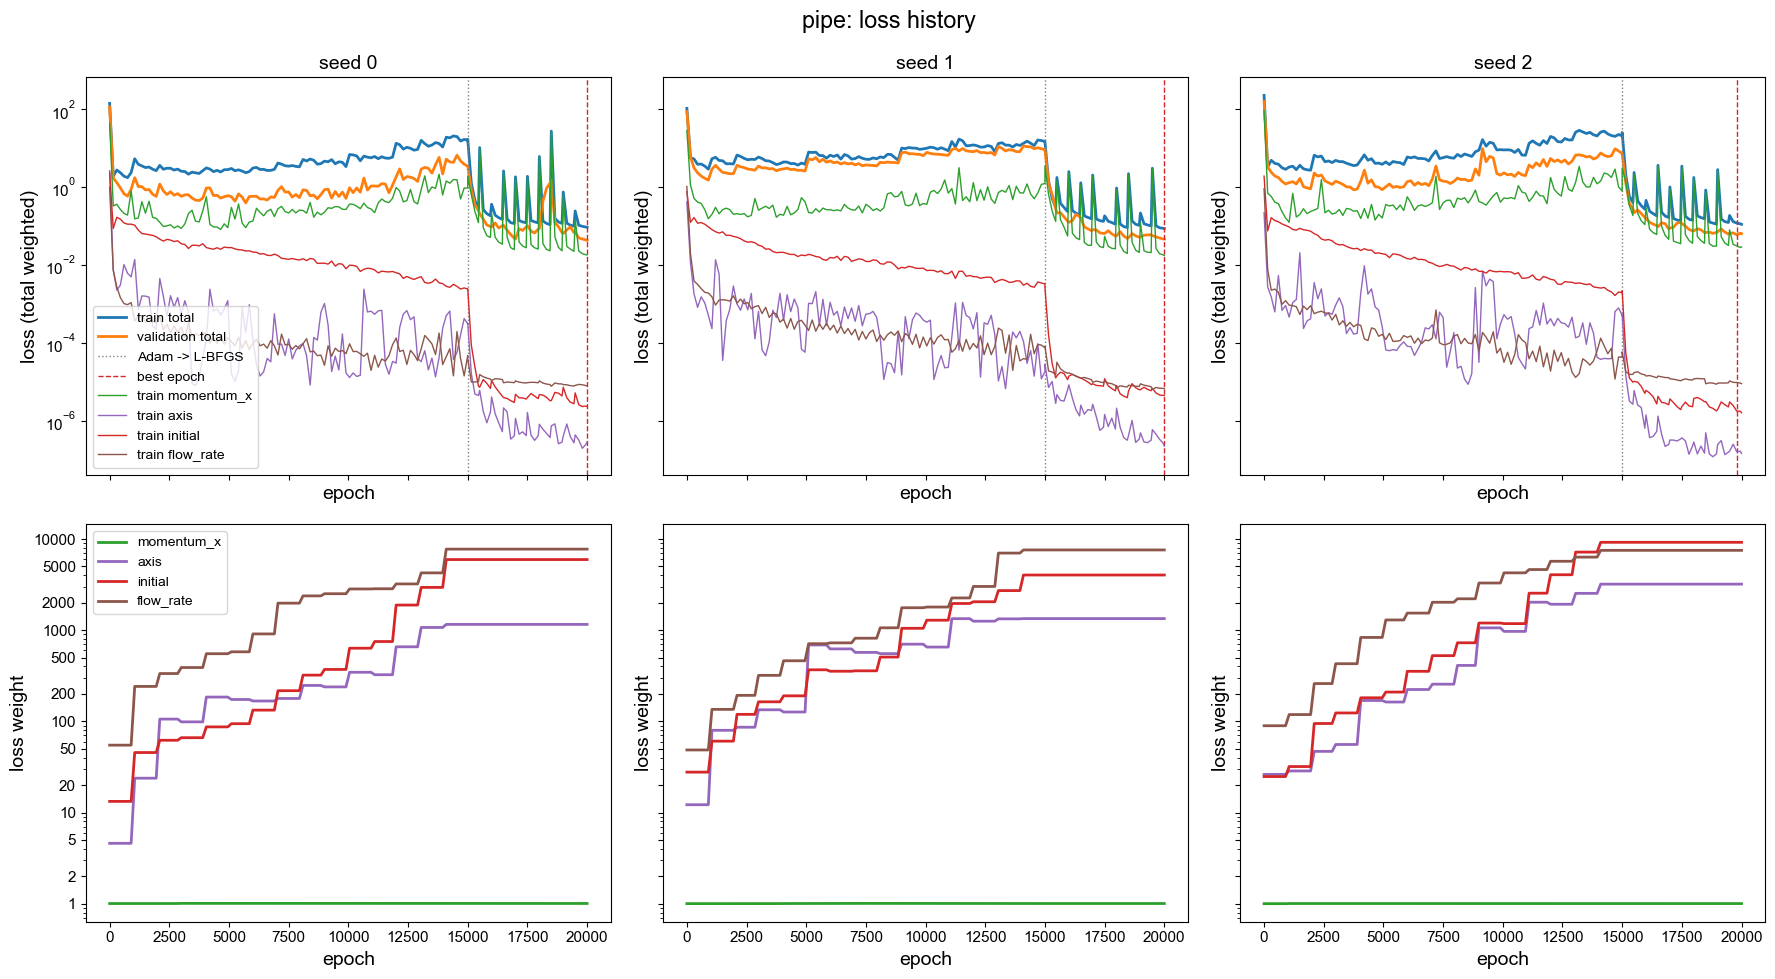

seed 0 best epoch 20000, validation terms: momentum_x=2.34e-02  axis=2.52e-07  initial=1.98e-06  flow_rate=9.03e-07   weights: momentum_x=1.01  axis=1.16e+03  initial=5.96e+03  flow_rate=7.75e+03
seed 1 best epoch 20000, validation terms: momentum_x=1.64e-02  axis=2.49e-07  initial=4.90e-06  flow_rate=1.31e-06   weights: momentum_x=1  axis=1.34e+03  initial=4.03e+03  flow_rate=7.59e+03
seed 2 best epoch 19800, validation terms: momentum_x=2.32e-02  axis=2.04e-07  initial=1.77e-06  flow_rate=2.59e-06   weights: momentum_x=1  axis=3.2e+03  initial=9.21e+03  flow_rate=7.52e+03


In [4]:
plot_loss("pipe")

## Performance

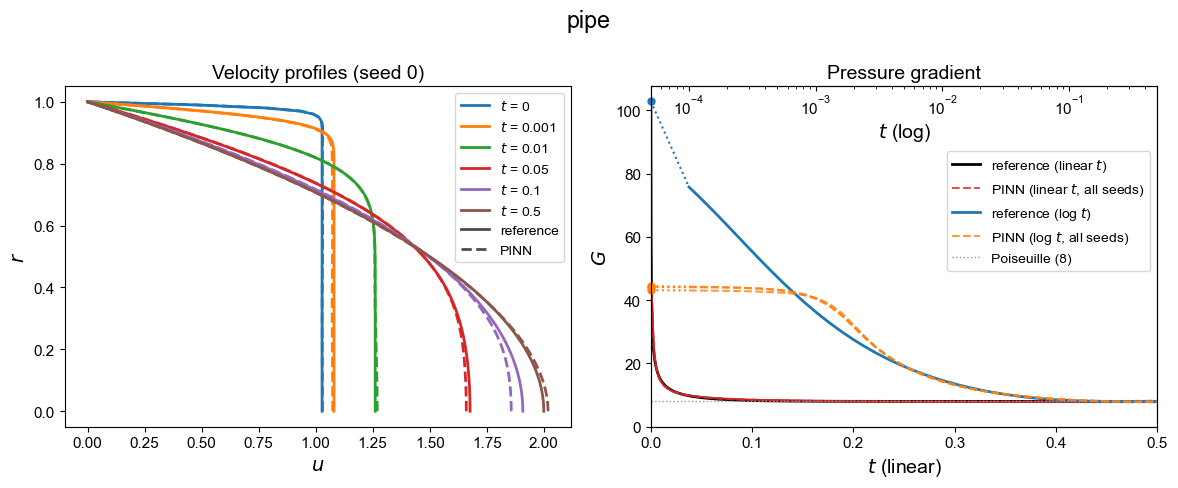

In [5]:
plot_performance("pipe")

# Channel

## Dimensional form

- **Independent variables**: $y$, $t$
- **Dependent variables**: $u(y, t)$, $G(t) := -\dfrac{1}{\rho}\dfrac{\partial p}{\partial x}$
- **Domain**: $0 \le y \le h$, $t \ge 0$

**Governing equation**

$$
\frac{\partial u}{\partial t} = G(t) + \nu\frac{\partial^2 u}{\partial y^2}
$$

**Flow-rate constraint**

$$
\int_0^h u\,\mathrm{d}y = hU
$$

**Boundary conditions**

$$
u(h, t) = 0, \qquad \left.\frac{\partial u}{\partial y}\right|_{y=0} = 0
$$

**Initial condition**

$$
u(y, 0) = U, \qquad 0 \le y < h
$$

## Nondimensional form

$$
\hat y = \frac{y}{h}, \qquad \hat t = \frac{\nu t}{h^2}, \qquad \hat u = \frac{u}{U}, \qquad \hat G = \frac{h^2}{\nu U}\,G
$$

Hats dropped below.

- **Independent variables**: $y$, $t$
- **Dependent variables**: $u(y, t)$, $G(t)$
- **Domain**: $0 \le y \le 1$, $0 \le t \le 0.5$

**Governing equation**

$$
\frac{\partial u}{\partial t} = G(t) + \frac{\partial^2 u}{\partial y^2}
$$

**Flow-rate constraint**

$$
\int_0^1 u\,\mathrm{d}y = 1
$$

**Boundary conditions**

$$
u(1, t) = 0, \qquad \left.\frac{\partial u}{\partial y}\right|_{y=0} = 0
$$

**Initial condition**

$$
u(y, 0) = 1 \quad (0 \le y < 1)
\quad\longrightarrow\quad
u(y, 0) = U_c\tanh\!\left(\frac{1 - y}{\delta}\right)
$$

$$
\delta = 0.02, \qquad
U_c = \frac{1}{\delta\ln\cosh(1/\delta)} \approx 1.014
$$

## Analytical solution

**Step initial condition**

$$
u(y, t) = \tfrac32(1 - y^2) + 2\sum_{n=1}^{\infty} \frac{\cos(\lambda_n y) - \cos\lambda_n}{\lambda_n^2 \cos\lambda_n}\, e^{-\lambda_n^2 t},
\qquad
G(t) = 3 + 2\sum_{n=1}^{\infty} e^{-\lambda_n^2 t},
\qquad
\tan\lambda_n = \lambda_n \quad (\lambda_n > 0)
$$

**Tanh initial condition** (reference in the plots)

$$
u(y, t) = \tfrac32(1 - y^2) + \sum_{n=1}^{\infty} c_n \big[\cos(\lambda_n y) - \cos\lambda_n\big] e^{-\lambda_n^2 t},
\qquad
G(t) = 3 + \sum_{n=1}^{\infty} c_n\, \lambda_n \sin\lambda_n\, e^{-\lambda_n^2 t}
$$

$$
c_n = \frac{\int_0^1 \big[U_c\tanh\big((1 - y)/\delta\big) - \tfrac32(1 - y^2)\big]\big[\cos(\lambda_n y) - \cos\lambda_n\big]\,\mathrm{d}y}{\sin^2\lambda_n / 2}
$$

**Steady state**

$$
\lim_{t \to \infty} u = \tfrac32(1 - y^2), \qquad \lim_{t \to \infty} G = 3
$$

## PINN setup

- **Input**: $(y, t, \tau)$, $\tau = \log(1 + t/\varepsilon)$, $\varepsilon = \delta^2 = 4\times10^{-4}$; each input mapped affinely to $[-1, 1]$.
- **Output**: $(N_u, N_G)$.
- **Output transform**: $u = (1 - y)\,N_u$, $G(t) = N_G(0, t)$.
- **Network**: 4 hidden layers of 32, tanh.
- **Loss**: $\mathcal{L} = \sum_i \lambda_i \mathcal{L}_i$ over four mean-squared residuals: PDE $u_t - G - u_{yy}$, centerline $u_y(0, t)$, initial $u(y, 0) - U_c\tanh\big((1 - y)/\delta\big)$, flow rate $\int_0^1 u\,\mathrm{d}y - 1$ (Gauss–Legendre quadrature).
- **Loss balancing** (gradient norm): weights updated every 1000 Adam steps, frozen during L-BFGS.

$$
\hat\lambda_i = \frac{\sum_j \lVert \nabla_\theta \mathcal{L}_j \rVert}{\lVert \nabla_\theta \mathcal{L}_i \rVert},
\qquad
\lambda_i \leftarrow 0.9\,\lambda_i + 0.1\,\hat\lambda_i
$$

- **Collocation**: $t = 0.5\,\xi^2$ ($\xi$ uniform, denser at early $t$), resampled periodically.
- **RAD**: part of the interior points and all boundary points drawn with residual-based weights.
- **Optimization**: Adam 15 000 steps, then L-BFGS 5 000 iterations; best model = lowest validation loss within the L-BFGS stage.

## Training

In [6]:
RUN_CHANNEL = False
FORCE_CHANNEL = False
train("channel", run=RUN_CHANNEL, force=FORCE_CHANNEL)

[adam] epoch      0  loss=6.8325e+02  pde=1.77e+02  bc=6.40e+00  weights=[1 24.6 80.6 199]  elapsed=0s
[adam] epoch    500  loss=1.5241e+01  pde=2.52e+00  bc=1.60e-01  weights=[1 24.6 80.6 199]  elapsed=12s
[adam] epoch   1000  loss=1.8534e+01  pde=5.64e-01  bc=1.03e-01  weights=[1 30 177 278]  elapsed=23s
[adam] epoch   1500  loss=9.3447e+00  pde=8.12e-01  bc=4.84e-02  weights=[1 30 177 278]  elapsed=34s
[adam] epoch   2000  loss=9.2169e+00  pde=5.15e-01  bc=3.76e-02  weights=[1 47.5 231 495]  elapsed=45s
[adam] epoch   2500  loss=7.3907e+00  pde=4.46e-01  bc=3.01e-02  weights=[1 47.5 231 495]  elapsed=59s
[adam] epoch   3000  loss=7.4788e+00  pde=9.56e-01  bc=2.15e-02  weights=[1 87.8 311 765]  elapsed=70s
[adam] epoch   3500  loss=6.8261e+00  pde=7.29e-01  bc=1.98e-02  weights=[1 87.8 311 765]  elapsed=81s
[adam] epoch   4000  loss=7.4313e+00  pde=5.89e-01  bc=1.61e-02  weights=[1 198 427 886]  elapsed=92s
[adam] epoch   4500  loss=6.8634e+00  pde=7.29e-01  bc=1.44e-02  weights=[1 1

## Loss

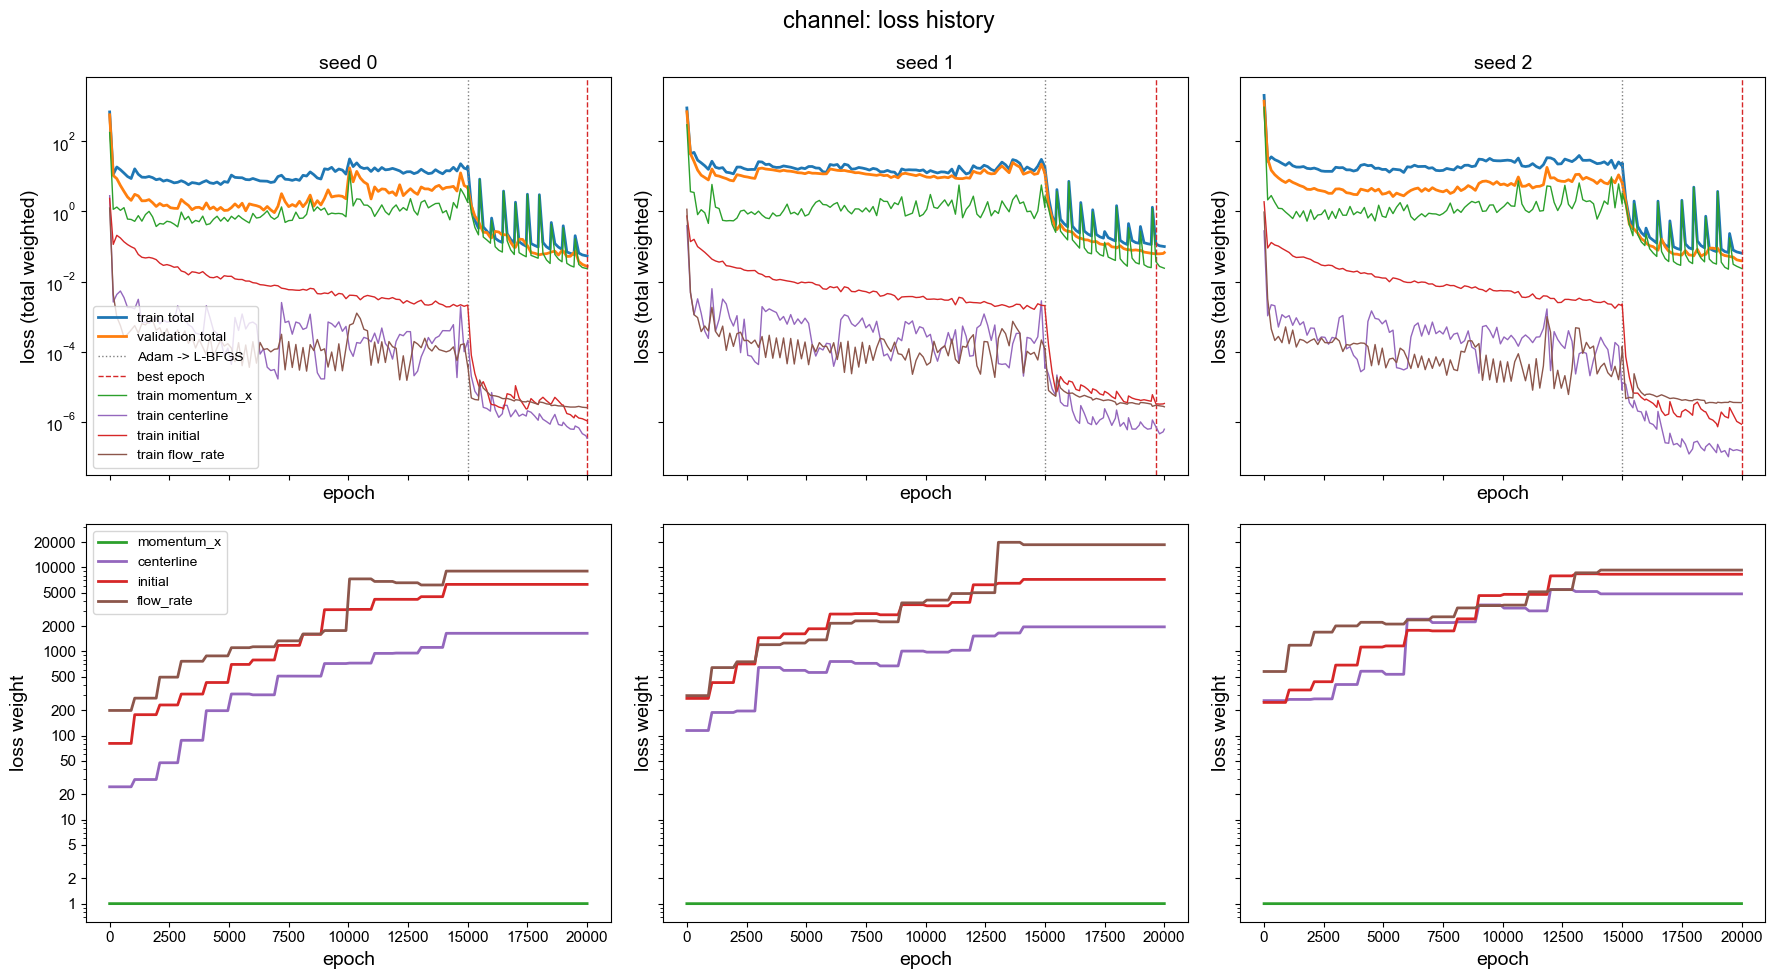

seed 0 best epoch 20000, validation terms: momentum_x=1.79e-02  centerline=3.10e-07  initial=1.01e-06  flow_rate=2.82e-07   weights: momentum_x=1  centerline=1.64e+03  initial=6.28e+03  flow_rate=9.04e+03
seed 1 best epoch 19650, validation terms: momentum_x=2.60e-02  centerline=4.64e-07  initial=3.33e-06  flow_rate=5.77e-07   weights: momentum_x=1  centerline=1.96e+03  initial=7.2e+03  flow_rate=1.86e+04
seed 2 best epoch 20000, validation terms: momentum_x=2.13e-02  centerline=1.54e-07  initial=9.81e-07  flow_rate=9.54e-07   weights: momentum_x=1  centerline=4.85e+03  initial=8.29e+03  flow_rate=9.3e+03


In [7]:
plot_loss("channel")

## Performance

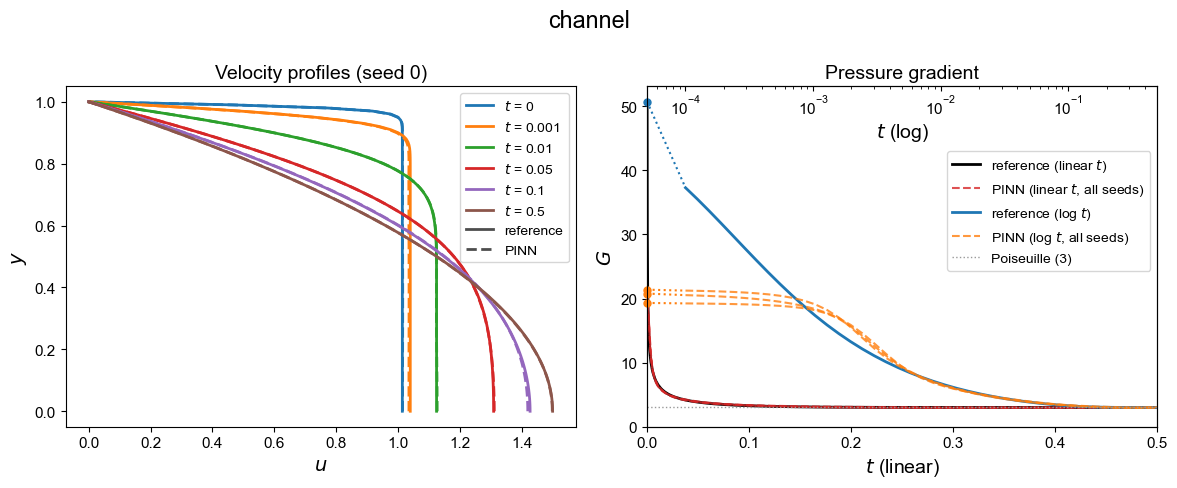

In [8]:
plot_performance("channel")